<a href="https://colab.research.google.com/github/TlameloPatlakwe/AI-for-S-E-Projects/blob/main/BUILDING_A_SUPERVISED_MACHINE_LEARNING_MODEL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**BUILDING A SUPERVISED MACHINE LEARNING MODEL**

**Project:** Predicting the Factor of Safety for Heterogeneous Slope using Machine Learning Techniques

**Objective:** Develop and compare two supervised machine learning models for predicting the Factor of Safety using geotechnical parameters

**Problem Type:** Regression



In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:

from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

data = pd.read_excel(filename) if filename.lower().endswith((".xlsx", ".xls")) else pd.read_csv(filename)

print("Dataset shape:", data.shape)
display(data.head())
print("Column names:", data.columns.tolist())


Saving MAIN DATASET (1).xlsx to MAIN DATASET (1).xlsx
Dataset shape: (197, 29)


,CASE,COMPRESSIVE STRENGTH(KIMBERLITE),mb,s,a,COMPRESSIVE STRENGTH(CS),mb.1,s.1,a.1,COMPRESSIVE STRENGTH(DOLOMITE),...,s.4,a.4,TENSILE STRENGTH(SAND),FRICTION ANGLE,COHESION,TENSILE STRENGTH(CALCRETE),FRICTION ANGLE.1,COHESION.1,RU,FoS
0,1,36064.238781,1.917204,0.004320,0.510723,119041.677640,0.530627,0.001319,0.526136,289562.638924,...,0.000819,0.502310,1,33.738229,1,1,29.868210,1,0.075,1.15
1,2,31972.366503,1.521989,0.003706,0.482796,159679.036671,0.536456,0.001330,0.530334,349270.527018,...,0.000677,0.521358,1,35.070238,1,1,31.408754,1,0.075,1.16
2,3,49284.275233,1.866600,0.003728,0.527070,112964.325185,0.546670,0.001301,0.498686,254765.340051,...,0.001190,0.497564,1,36.104115,1,1,30.813811,1,0.075,1.16
3,4,35688.098048,1.161285,0.004989,0.511970,134780.822237,0.493544,0.001742,0.498678,310609.492012,...,0.000905,0.509303,1,33.627620,1,1,29.443068,1,0.075,1.15
4,5,48537.055490,1.282094,0.003034,0.518658,125591.834894,0.498928,0.001702,0.490356,343384.475454,...,0.000723,0.493015,1,34.744877,1,1,28.520856,1,0.075,1.46


Column names: ['CASE', 'COMPRESSIVE STRENGTH(KIMBERLITE)', 'mb', 's', 'a', 'COMPRESSIVE STRENGTH(CS)', 'mb.1', 's.1', 'a.1', 'COMPRESSIVE STRENGTH(DOLOMITE)', 'mb.2', 's.2', 'a.2', 'COMPRESSIVE STRENGTH(QUARZITIC SHALE)', 'mb.3', 's.3', 'a.3', 'COMPRESSIVE STRENGTH(LAMINATED SHALE)', 'mb.4', 's.4', 'a.4', 'TENSILE STRENGTH(SAND)', 'FRICTION ANGLE', 'COHESION', 'TENSILE STRENGTH(CALCRETE)', 'FRICTION ANGLE.1', 'COHESION.1', 'RU', 'FoS']


In [3]:


data.columns = data.columns.str.strip()


target = "FoS"


exclude = ["FoS", "CASE"]

X = data.drop(columns=exclude, errors="ignore")
X = X.select_dtypes(include=np.number)

y = pd.to_numeric(data[target], errors="coerce")


valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

print("Input features:")
print(X.columns.tolist())

print("\nTarget:", target)
print("Number of cases:", len(y))


Input features:
['COMPRESSIVE STRENGTH(KIMBERLITE)', 'mb', 's', 'a', 'COMPRESSIVE STRENGTH(CS)', 'mb.1', 's.1', 'a.1', 'COMPRESSIVE STRENGTH(DOLOMITE)', 'mb.2', 's.2', 'a.2', 'COMPRESSIVE STRENGTH(QUARZITIC SHALE)', 'mb.3', 's.3', 'a.3', 'COMPRESSIVE STRENGTH(LAMINATED SHALE)', 'mb.4', 's.4', 'a.4', 'TENSILE STRENGTH(SAND)', 'FRICTION ANGLE', 'COHESION', 'TENSILE STRENGTH(CALCRETE)', 'FRICTION ANGLE.1', 'COHESION.1', 'RU']

Target: FoS
Number of cases: 197


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Testing cases:", len(X_test))


Training cases: 157
Testing cases: 40


In [5]:

# RF
rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
)

# SVR
svr_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVR(kernel="rbf")
)

rf_model.fit(X_train, y_train)
svr_model.fit(X_train, y_train)

print("Both models trained successfully.")


Both models trained successfully.


In [6]:

rf_pred = rf_model.predict(X_test)
svr_pred = svr_model.predict(X_test)

predictions = pd.DataFrame({
    "Actual FoS": y_test.to_numpy(),
    "RF Predicted FoS": rf_pred,
    "SVR Predicted FoS": svr_pred
})

display(predictions.head(10))


,Actual FoS,RF Predicted FoS,SVR Predicted FoS
0,0.82,0.78880,0.911791
1,0.81,0.79860,0.949178
2,1.50,1.42540,1.392901
3,1.32,1.32422,1.234602
4,0.61,0.71060,0.606907
5,0.78,0.73120,0.801191
6,1.37,1.31744,1.280137
7,1.39,1.32118,1.289250
8,1.44,1.42300,1.143140
9,0.79,0.71410,0.659395


In [7]:

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

results = pd.DataFrame([
    evaluate_model("Random Forest", y_test, rf_pred),
    evaluate_model("SVR", y_test, svr_pred)
])

display(results.round(4))


,Model,R2,MAE,MSE,RMSE
0,Random Forest,0.9325,0.0660,0.0070,0.0837
1,SVR,0.7614,0.1254,0.0247,0.1573


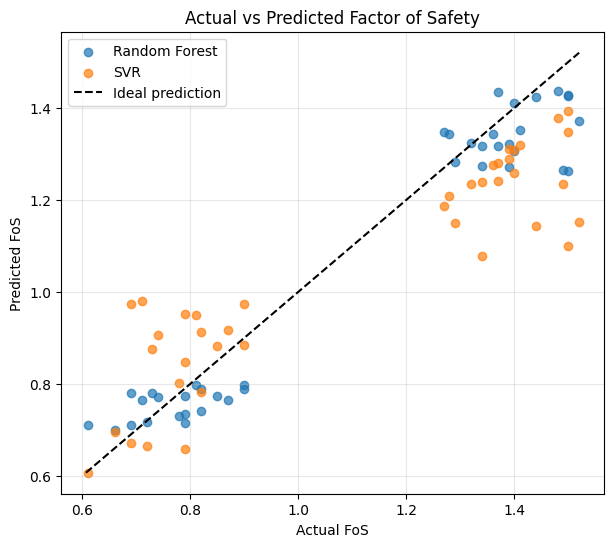

In [8]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, rf_pred, label="Random Forest", alpha=0.7)
plt.scatter(y_test, svr_pred, label="SVR", alpha=0.7)

limits = [
    min(y_test.min(), rf_pred.min(), svr_pred.min()),
    max(y_test.max(), rf_pred.max(), svr_pred.max())
]

plt.plot(limits, limits, "k--", label="Ideal prediction")

plt.xlabel("Actual FoS")
plt.ylabel("Predicted FoS")
plt.title("Actual vs Predicted Factor of Safety")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**DISCUSSION OF RESULTS**


Random Forest(RF) outperformed Support Vector Regression (SVR) in predicting the Factor of Safety.RF achieved a higher R² of 0.9332 as compared to 0.7614 for SVR, indicating that it explained approximately 93.3% of the variation in FoS.

It also recorded lower MAE (0.0661) and RMSE (0.0832), demostrating greater prediction accuracy.These findings suggest that RF proved more effective with capturing the nonlinear relationship between the geotechnical parameters and stability.